# Ward hierarchical clustering on the station-window features

Same four steps as `03_kmeans_example.ipynb`, so the shared evaluation reads every method the same way:

1. **Read** the feature table **straight from S3**: the Parquet files Athena writes to `s3://<bucket>/curated/features/` (`sql/06_features.sql`). This needs AWS access (`export AWS_PROFILE=data-mining` for teammates; see `docs/TEAM_SETUP.md`).
2. **Split** the identifying columns from the 17 features. The features become the matrix `X` (244 rows x 17 columns, already z-scored).
3. **Fit** Ward on `X`.
4. **Save** one label per row in the shared format, `results/labels/ward.parquet`.

Ward merges, at every step, the two clusters whose union increases the within-cluster sum of squares (SSE) the least, the same objective k-means minimises. It is only defined for Euclidean distance, which is why `X` is z-scored first. Ward is deterministic: there are no random starts, so no restarts and no seed for the fit. `SEED` below is only used for the resampling stability check. k from 2 to 10, as for k-means.

In [1]:
from pathlib import Path
import awswrangler as wr
import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REGION = "ap-south-1"
session = boto3.Session(region_name=REGION)
ACCOUNT_ID = session.client("sts").get_caller_identity()["Account"]
BUCKET = f"dubai-metro-profiling-{ACCOUNT_ID}"
FEATURES_S3 = f"s3://{BUCKET}/curated/features/"            # z-scored, built by Athena
UNSCALED_S3 = f"s3://{BUCKET}/curated/features_unscaled/"   # same rows before scaling
HAND_LABELS = ROOT / "results" / "hand_labels.csv"
LABELS_DIR = ROOT / "results" / "labels"
METRICS_DIR = ROOT / "results" / "metrics"
FIGURES = ROOT / "figures"
for folder in (LABELS_DIR, METRICS_DIR, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42            # resampling only; Ward itself has no randomness
K_RANGE = range(2, 11)
RESAMPLES, FRACTION = 100, 0.8

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.edgecolor": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 130})
pd.set_option("display.width", 200, "display.max_columns", 30)


def cut(Z, k):
    """0-based labels for exactly k clusters from a scipy linkage matrix."""
    labels = fcluster(Z, t=k, criterion="maxclust") - 1      # fcluster is 1-based
    if len(np.unique(labels)) != k:
        raise ValueError(f"maxclust gave {len(np.unique(labels))} clusters for k={k} (tied merge heights)")
    return labels


def sse(X, labels):
    """Within-cluster sum of squares, the same definition as KMeans.inertia_."""
    return float(sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels)))

## 1. Read the feature table from S3 and build X

In [2]:
df = wr.s3.read_parquet(FEATURES_S3, boto3_session=session).sort_values(["location_id", "win"]).reset_index(drop=True)
print("read", len(df), "rows from", FEATURES_S3.replace(ACCOUNT_ID, "<account>"))
ID_COLUMNS = ["win", "location_id", "station", "timed_taps", "check_ins", "check_outs"]
FEATURE_COLUMNS = [c for c in df.columns if c not in ID_COLUMNS]
X = df[FEATURE_COLUMNS].to_numpy()
n = X.shape[0]
print("X shape:", X.shape)
print("features:", FEATURE_COLUMNS)
print("duplicate rows:", n - len(np.unique(X, axis=0)))
assert X.shape == (244, 17) and not np.isnan(X).any()

read 244 rows from s3://dubai-metro-profiling-<account>/curated/features/
X shape: (244, 17)
features: ['check_in_share_00_07', 'check_in_share_07_10', 'check_in_share_10_16', 'check_in_share_16_20', 'check_in_share_20_24', 'check_out_share_00_07', 'check_out_share_07_10', 'check_out_share_10_16', 'check_out_share_16_20', 'check_out_share_20_24', 'net_flow_00_07', 'net_flow_07_10', 'net_flow_10_16', 'net_flow_16_20', 'net_flow_20_24', 'weekend_share', 'volume_share']
duplicate rows: 0


## 2. Choose k
Build the Ward tree once, then cut it at every k from 2 to 10 and record the same four internal metrics as k-means. `AgglomerativeClustering` has no `inertia_`, so SSE is computed from the cluster means exactly as k-means defines inertia, which keeps the two elbow plots comparable. `merge_gap` is how far the cut can move without changing k: a large gap means that set of clusters stays apart over a wide range of thresholds.

SSE always falls as k grows, so look for the elbow; silhouette is better when higher, Davies-Bouldin when lower, Calinski-Harabasz when higher. Ward height grows fastest near top of the tree, so the largest merge gaps appear at small k. Silhouette does not agree here, which is discussed when K is chosen

In [3]:
Z = linkage(X, method="ward")              # raw observations; Euclidean
assert np.all(np.diff(Z[:, 2]) >= 0), "Ward heights should never decrease"
print(f"cophenetic correlation: {cophenet(Z, pdist(X))[0]:.3f} (how faithfully the tree keeps the distances, not cluster quality)")

rows = []
for k in K_RANGE:
    labels_k = cut(Z, k)
    rows.append({"k": k, "sse": sse(X, labels_k),
                 "silhouette": silhouette_score(X, labels_k),
                 "davies_bouldin": davies_bouldin_score(X, labels_k),
                 "calinski_harabasz": calinski_harabasz_score(X, labels_k),
                 "smallest_cluster": int(np.bincount(labels_k).min()),
                 "merge_gap": Z[n - k, 2] - Z[n - k - 1, 2]})
sweep = pd.DataFrame(rows).round(4)
sweep.to_csv(METRICS_DIR / "ward_k_sweep.csv", index=False)
sweep

cophenetic correlation: 0.527 (how faithfully the tree keeps the distances, not cluster quality)


,k,sse,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster,merge_gap
0,2,2911.5457,0.2522,1.2242,102.7708,83,12.8888
1,3,2232.9691,0.2423,1.3320,103.3428,40,10.5136
2,4,1886.4414,0.2625,1.4938,95.9079,40,6.0741
3,5,1681.3720,0.2681,1.4031,87.6552,18,2.6236
4,6,1525.9942,0.2785,1.3151,81.7876,6,2.6698
5,7,1414.1166,0.2687,1.2688,76.3646,6,0.4441
6,8,1308.7833,0.2168,1.3481,73.1383,6,0.2716
7,9,1207.3549,0.2355,1.2524,71.5460,6,2.2087
8,10,1134.9458,0.2223,1.3516,69.0248,6,0.2171


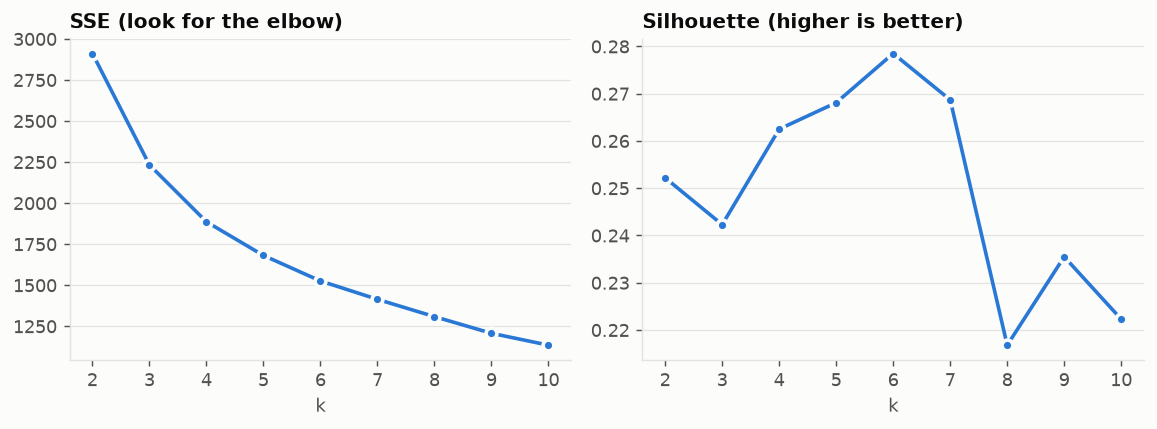

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, column, title in ((axes[0], "sse", "SSE (look for the elbow)"),
                          (axes[1], "silhouette", "Silhouette (higher is better)")):
    ax.plot(sweep.k, sweep[column], color=SERIES[0], lw=2, marker="o", ms=6, mec=SURFACE, mew=2)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("k")
    ax.set_xticks(list(K_RANGE))
    ax.grid(axis="y", color=GRID, lw=0.7)
fig.tight_layout()
fig.savefig(FIGURES / "ward_k_selection.png", dpi=200)

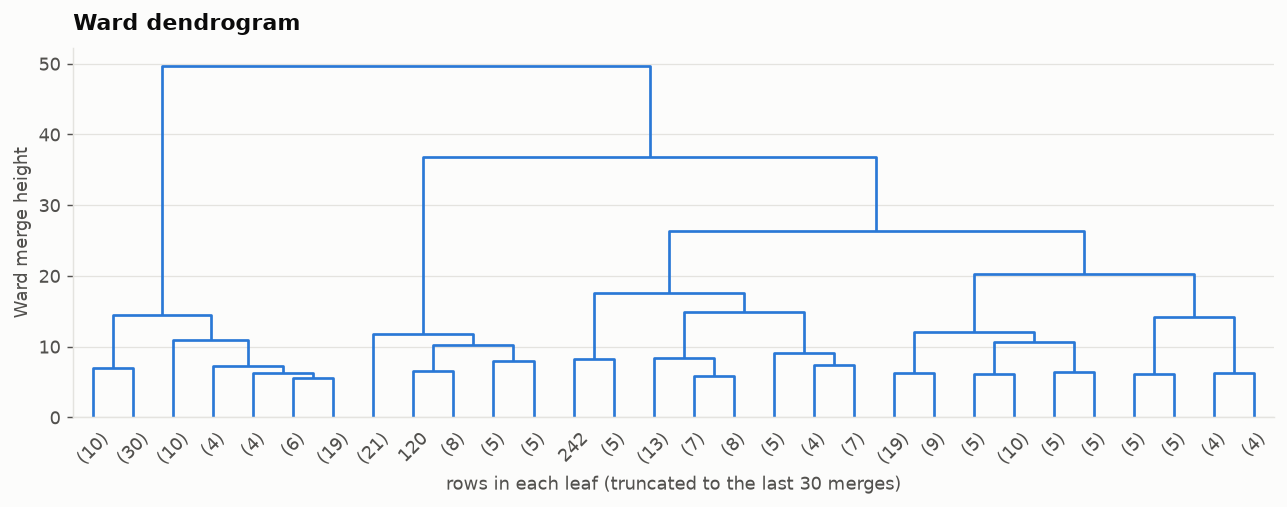

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, ax=ax, truncate_mode="lastp", p=30, show_leaf_counts=True,
           color_threshold=0, above_threshold_color=SERIES[0])
ax.set_ylabel("Ward merge height")
ax.set_xlabel("rows in each leaf (truncated to the last 30 merges)")
ax.grid(axis="y", color=GRID, lw=0.7)
ax.set_title("Ward dendrogram", loc="left", fontsize=12, fontweight="bold", pad=10)
fig.tight_layout()
fig.savefig(FIGURES / "ward_dendrogram.png", dpi=200)

## 3. Fit the chosen k
`K` is the team's choice after reading the sweep. It starts at the k with the best silhouette, the same rule as k-means; change it here if the elbow, the dendrogram gaps, the stability check (section 7) or the cluster profiles argue for another value.

The final labels come from sklearn's `AgglomerativeClustering`, to keep the same estimator interface as the other methods. For unconstrained Ward it calls the same algorithm as scipy, so the two partitions must agree (ARI = 1; label numbers themselves are arbitrary, so they are not compared with `==`).

In [6]:
K = 6 #isolates the visitor-destination group: Burj Khalifa/Dubai Mall in every window, plus EXPO in W21/22 (Expo 2020). k=2 and k=3 merge it away.
model = AgglomerativeClustering(n_clusters=K, linkage="ward")
cluster = model.fit_predict(X)
assert np.isclose(adjusted_rand_score(cluster, cut(Z, K)), 1.0), "scipy and sklearn disagree"
assert np.isclose(sse(X, cluster), 0.5 * np.sum(Z[: n - K, 2] ** 2)), "SSE does not match the tree"
print(f"K = {K}")
print(sweep[sweep.k == K].to_string(index=False))
print("rows per cluster:", np.bincount(cluster).tolist())

K = 6
 k       sse  silhouette  davies_bouldin  calinski_harabasz  smallest_cluster  merge_gap
 6 1525.9942      0.2785          1.3151            81.7876                 6     2.6698
rows per cluster: [44, 83, 40, 18, 53, 6]


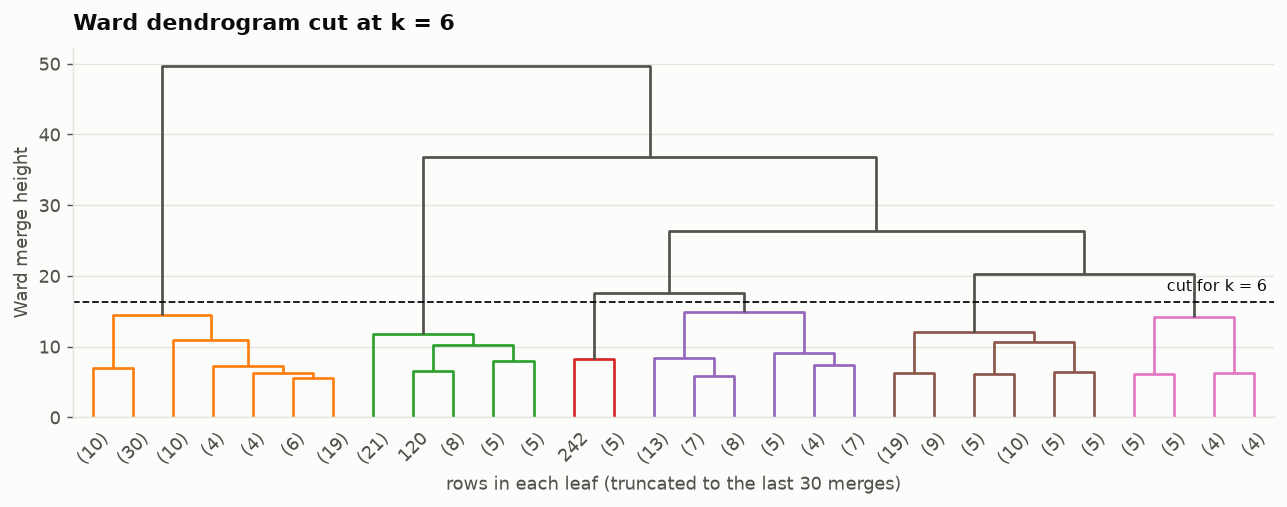

In [7]:
cut_height = (Z[n - K - 1, 2] + Z[n - K, 2]) / 2     # between the last merge kept and the next one
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, ax=ax, truncate_mode="lastp", p=30, show_leaf_counts=True,
           color_threshold=cut_height, above_threshold_color=MUTED)
ax.axhline(cut_height, color=INK, ls="--", lw=1)
ax.annotate(f"cut for k = {K}", (ax.get_xlim()[1], cut_height), xytext=(-4, 4), textcoords="offset points",
            ha="right", va="bottom", color=INK, fontsize=9)
ax.set_ylabel("Ward merge height")
ax.set_xlabel("rows in each leaf (truncated to the last 30 merges)")
ax.grid(axis="y", color=GRID, lw=0.7)
ax.set_title(f"Ward dendrogram cut at k = {K}", loc="left", fontsize=12, fontweight="bold", pad=10)
fig.tight_layout()
fig.savefig(FIGURES / "ward_dendrogram_cut.png", dpi=200)

## 4. Save labels in the shared format
Every method writes the same columns, so one evaluation script reads them all. `alpha` is only used by ST-GRSC, so it is NaN here.

In [8]:
labels = df[["win", "location_id", "station"]].copy()
labels["method"] = "ward"
labels["k"] = K
labels["alpha"] = np.nan
labels["cluster"] = cluster
assert list(labels.columns) == ["win", "location_id", "station", "method", "k", "alpha", "cluster"]
labels.to_parquet(LABELS_DIR / "ward.parquet", index=False)
labels.head()

,win,location_id,station,method,k,alpha,cluster
0,W17/18,128,centrepoint,ward,6,NaN,1
1,W18/19,128,centrepoint,ward,6,NaN,1
2,W19/20,128,centrepoint,ward,6,NaN,1
3,W21/22,128,centrepoint,ward,6,NaN,1
4,W24/25,128,centrepoint,ward,6,NaN,1


## 5. What each cluster looks like
Average unscaled features per cluster. These profiles are what you name the clusters from (for example: morning arrivals and evening departures suggest a business area). Names are interpretations, not findings.

In [9]:
unscaled = wr.s3.read_parquet(UNSCALED_S3, boto3_session=session)
profile = unscaled.merge(labels[["win", "location_id", "cluster"]], on=["win", "location_id"])
summary = profile.groupby("cluster")[FEATURE_COLUMNS].mean()
summary.insert(0, "rows", profile.groupby("cluster").size())
summary.round(3).to_csv(METRICS_DIR / "ward_cluster_profiles.csv")
summary.round(3).T

cluster,0,1,2,3,4,5
rows,44.000,83.000,40.000,18.000,53.000,6.000
check_in_share_00_07,0.031,0.067,0.017,0.058,0.034,0.023
check_in_share_07_10,0.127,0.252,0.069,0.143,0.133,0.033
check_in_share_10_16,0.280,0.272,0.233,0.321,0.267,0.169
check_in_share_16_20,0.335,0.267,0.542,0.314,0.416,0.389
check_in_share_20_24,0.227,0.142,0.138,0.164,0.150,0.386
check_out_share_00_07,0.029,0.033,0.076,0.092,0.044,0.023
check_out_share_07_10,0.142,0.106,0.417,0.134,0.265,0.173
check_out_share_10_16,0.311,0.224,0.246,0.247,0.264,0.363
check_out_share_16_20,0.349,0.382,0.165,0.256,0.256,0.325


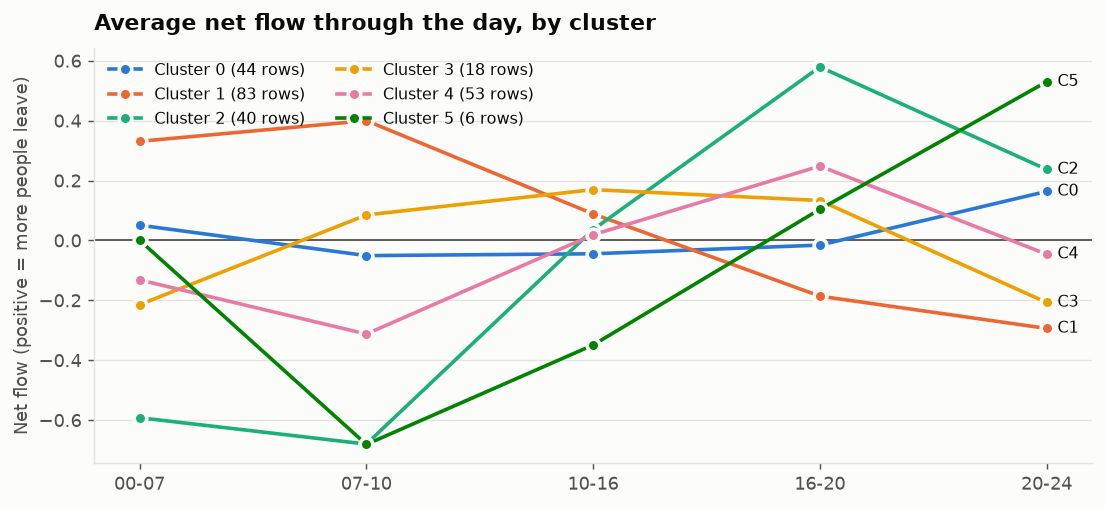

In [10]:
bands = ["00_07", "07_10", "10_16", "16_20", "20_24"]
band_labels = ["00-07", "07-10", "10-16", "16-20", "20-24"]
fig, ax = plt.subplots(figsize=(8.6, 4))
ax.axhline(0, color=MUTED, lw=1)
for c in summary.index:
    values = [summary.loc[c, f"net_flow_{b}"] for b in bands]
    ax.plot(band_labels, values, color=SERIES[c % len(SERIES)], lw=2, marker="o", ms=7, mec=SURFACE, mew=2,
            label=f"Cluster {c} ({int(summary.loc[c, 'rows'])} rows)")
    ax.annotate(f"C{c}", (len(bands) - 1, values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.set_ylabel("Net flow (positive = more people leave)")
ax.grid(axis="y", color=GRID, lw=0.7)
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
ax.set_title("Average net flow through the day, by cluster", loc="left", fontsize=12, fontweight="bold", pad=10)
fig.tight_layout()
fig.savefig(FIGURES / "ward_cluster_net_flow.png", dpi=200)

## 6. Check against the 12 validation labels
Each labelled station has up to five rows (one per window). For each station: the cluster it falls in most often, and in how many of its windows.

In [11]:
hand = pd.read_csv(HAND_LABELS)
check = labels.merge(hand[["location_id", "expected_type", "seen_in_charts"]], on="location_id")
per_station = (check.groupby(["station", "expected_type", "seen_in_charts"])["cluster"]
               .agg(main_cluster=lambda s: s.mode().iloc[0],
                    windows_in_main=lambda s: int((s == s.mode().iloc[0]).sum()),
                    windows=lambda s: len(s))
               .reset_index().sort_values(["main_cluster", "expected_type"]))
per_station.to_csv(METRICS_DIR / "ward_vs_hand_labels.csv", index=False)
per_station

,station,expected_type,seen_in_charts,main_cluster,windows_in_main,windows
10,Oud Metha,Education,no,0,5,5
8,Ibn Battuta,Shopping and leisure,no,0,5,5
9,Mall of the Emirates,Shopping and leisure,yes,0,5,5
1,Al Ghubaiba,Transfer and hub,no,0,5,5
2,Al Rigga,Mixed,no,1,5,5
11,Stadium,Residential,no,1,5,5
3,BurJuman,Transfer and hub,yes,1,5,5
5,Dubai Healthcare City,Business,no,2,5,5
6,EXPO,Shopping and leisure,no,2,1,2
0,Airport Terminal 3,Airport,yes,3,5,5


In [12]:
pd.crosstab(per_station.expected_type, per_station.main_cluster)

main_cluster,0,1,2,3,4
expected_type,,,,,
Airport,0,0,0,1,0
Business,0,0,1,0,1
Education,1,0,0,0,0
Mixed,0,1,0,0,1
Residential,0,1,0,0,0
Shopping and leisure,2,0,1,0,0
Transfer and hub,1,1,0,0,0


## 7. Stability and agreement with k-means
Ward has no random start, so its only sensitivity is to the data. Refit on 100 random 80% subsets of the rows and compare each subset's labels with the full-data labels on the shared rows (ARI: 1 = identical partition, 0 = chance). Neighbouring k values are included, because a k that is clearly more stable is a strong argument for it. The seed is for the resampling only.

Then compare Ward with k-means on the same rows, joined by `win` and `location_id`.

In [13]:
rng = np.random.default_rng(SEED)
m = int(round(FRACTION * n))
subsets = [np.sort(rng.choice(n, size=m, replace=False)) for _ in range(RESAMPLES)]
stability = []
for k in sorted({max(2, K - 1), K, min(10, K + 1)}):
    ref = cut(Z, k)
    ari, skipped = [], 0
    for idx in subsets:
        try:
            ari.append(adjusted_rand_score(ref[idx], cut(linkage(X[idx], method="ward"), k)))
        except ValueError:
            skipped += 1
    ari = np.array(ari)
    stability.append({"k": k, "ari_mean": ari.mean(), "ari_sd": ari.std(),
                      "ari_p05": np.percentile(ari, 5), "ari_p95": np.percentile(ari, 95), "skipped": skipped})
stability = pd.DataFrame(stability).round(4)
stability.to_csv(METRICS_DIR / "ward_stability.csv", index=False)
stability

,k,ari_mean,ari_sd,ari_p05,ari_p95,skipped
0,5,0.7712,0.1251,0.5304,0.9454,0
1,6,0.7623,0.1202,0.5321,0.9440,0
2,7,0.7060,0.1163,0.5429,0.8825,0


## 8. Summary

The method sorted Dubai Metro stations into six groups based purely on when people tap in and out, with no information about what’s near each station. Those groups turned out to mean something: places people leave from in the morning and come back to at night, places they arrive at for work, the airport, malls and all-day mixed areas, and a small group of major visitor destinations.

It got the obvious ones right without being told. Airport Terminal 3 ended up on its own in a group whose pattern is late-night arrivals. The two shopping malls landed together. The residential station landed with the residential group.

The most interesting part is that stations almost never change group. Eleven of the twelve stations you had labels for stayed in the same group across all five time windows, spanning eight years. The one exception was EXPO, which moved into the visitor-destination group for the 2021 to 2022 window and out again afterwards, which is exactly when Expo 2020 was running there.

The honest caveat is that the groups overlap a fair amount, so the quality scores are modest rather than strong, and the EXPO change is a single case rather than a trend.

## Results
- k = 6, cluster sizes 83 / 53 / 44 / 40 / 18 / 6
- Silhouette 0.2785, stability ARI 0.762 (sd 0.120)
- Clusters separate residential origins, workplace destinations, the airport,
  mixed all-day stations and major visitor destinations
- 11 of the 12 labelled stations keep the same cluster across all five windows.
  The exception is EXPO, which sits in the visitor-destination cluster only in
  W21/22, the window covering Expo 2020